<a href="https://colab.research.google.com/github/sachitsaz/Computer-Vision/blob/main/3D-CV/01_Depth_Anything/cv_05_3_DepthAnything_models_Trade_off.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Comparing Depth Anything V2 Small vs Base
Depth8 Dataset - All Depth8 Images

In [ ]:
# Install required packages
!pip install -q transformers accelerate

import os
import time
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn.functional as F

from transformers import (
    AutoImageProcessor,
    AutoModelForDepthEstimation
)


In [ ]:
# 1. Configuration
dataset_path = "/content/drive/MyDrive/Computer Vision/05/Depth8_8pairs"

# All 8 Depth8 RGB images
image_paths = [
    os.path.join(dataset_path, f"image_{i:02d}.png")
    for i in range(1, 9)
]

# Corresponding ground-truth depth maps
gt_paths = [
    os.path.join(dataset_path, f"depth_{i:02d}.npy")
    for i in range(1, 9)
]


# Models to compare
models_to_test = {
    "Depth Anything V2 Small":
        "depth-anything/Depth-Anything-V2-Small-hf",

    "Depth Anything V2 Base":
        "depth-anything/Depth-Anything-V2-Base-hf"
}


# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nNumber of images:", len(image_paths))

Device: cuda
GPU: Tesla T4

Number of images: 8


In [ ]:
# 2. Check files
print("\nChecking dataset files...")

for image_path, gt_path in zip(image_paths, gt_paths):

    if not os.path.exists(image_path):
        raise FileNotFoundError(image_path)

    if not os.path.exists(gt_path):
        raise FileNotFoundError(gt_path)

    print(
        os.path.basename(image_path),
        "✓"
    )


Checking dataset files...
image_01.png ✓
image_02.png ✓
image_03.png ✓
image_04.png ✓
image_05.png ✓
image_06.png ✓
image_07.png ✓
image_08.png ✓



**Scale-and-shift alignment**

 Depth Anything produces relative depth.

 It we'll be fit:

     GT ≈ a * prediction + b

 using least squares over valid GT pixels.

 This converts the relative prediction into the metric
 scale of the ground truth for evaluation only.

In [ ]:
# 3. Scale-and-shift alignment
def align_depth(pred, gt):

    pred = pred.astype(np.float64)
    gt = gt.astype(np.float64)

    valid = (
        np.isfinite(gt) &
        np.isfinite(pred) &
        (gt > 0)
    )

    x = pred[valid]
    y = gt[valid]

    # Least-squares solution for:
    # y = a*x + b

    A = np.vstack([
        x,
        np.ones_like(x)
    ]).T

    a, b = np.linalg.lstsq(
        A,
        y,
        rcond=None
    )[0]

    aligned = a * pred + b

    return aligned.astype(np.float32), a, b

In [ ]:
# 4. Quality metrics
def calculate_metrics(pred, gt):

    valid = (
        np.isfinite(gt) &
        np.isfinite(pred) &
        (gt > 0)
    )

    pred_valid = pred[valid]
    gt_valid = gt[valid]

    # MAE
    mae = np.mean(
        np.abs(pred_valid - gt_valid)
    )

    # RMSE
    rmse = np.sqrt(
        np.mean(
            (pred_valid - gt_valid) ** 2
        )
    )

    # Absolute Relative Error
    abs_rel = np.mean(
        np.abs(pred_valid - gt_valid)
        / gt_valid
    )

    return mae, rmse, abs_rel

In [ ]:
# 5. Run one model
def evaluate_model(model_name, model_id):

    print("\n")
    print("=" * 70)
    print(model_name)
    print("=" * 70)

    # --------------------------------------------------------
    # Load processor
    # --------------------------------------------------------

    processor = AutoImageProcessor.from_pretrained(
        model_id
    )

    # --------------------------------------------------------
    # Load model
    # --------------------------------------------------------

    model = AutoModelForDepthEstimation.from_pretrained(
        model_id
    )

    model.to(device)
    model.eval()

    # --------------------------------------------------------
    # Warm-up
    # --------------------------------------------------------
    #
    # This prevents first-run overhead from affecting
    # the timing measurements.
    # --------------------------------------------------------

    warmup_image = Image.open(
        image_paths[0]
    ).convert("RGB")

    with torch.no_grad():

        warmup_inputs = processor(
            images=warmup_image,
            return_tensors="pt"
        )

        warmup_inputs = {
            k: v.to(device)
            for k, v in warmup_inputs.items()
        }

        _ = model(**warmup_inputs)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    # Clear memory before actual measurements

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    gc.collect()


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    model_results = []


    # ========================================================
    # Process all 8 images
    # ========================================================

    for image_path, gt_path in zip(
        image_paths,
        gt_paths
    ):

        image_name = os.path.basename(
            image_path
        )

        print(
            f"\nProcessing {image_name}..."
        )


        # ----------------------------------------------------
        # Load image and GT
        # ----------------------------------------------------

        image = Image.open(
            image_path
        ).convert("RGB")

        gt_depth = np.load(
            gt_path
        ).astype(np.float32)


        # ----------------------------------------------------
        # Preprocessing timing
        # ----------------------------------------------------

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        preprocess_start = time.perf_counter()

        inputs = processor(
            images=image,
            return_tensors="pt"
        )

        inputs = {
            k: v.to(device)
            for k, v in inputs.items()
        }

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        preprocess_time = (
            time.perf_counter()
            - preprocess_start
        )


        # ----------------------------------------------------
        # Input size
        # ----------------------------------------------------

        pixel_values = inputs["pixel_values"]

        input_height = pixel_values.shape[-2]
        input_width = pixel_values.shape[-1]

        input_size = (
            input_height,
            input_width
        )


        # ----------------------------------------------------
        # Model inference timing
        # ----------------------------------------------------

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inference_start = time.perf_counter()

        with torch.no_grad():

            outputs = model(
                **inputs
            )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inference_time = (
            time.perf_counter()
            - inference_start
        )


        # ----------------------------------------------------
        # Postprocessing timing
        # ----------------------------------------------------

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        postprocess_start = time.perf_counter()

        predicted_depth = (
            outputs.predicted_depth
        )

        # Resize prediction to original image size

        predicted_depth = predicted_depth.unsqueeze(1)

        predicted_depth = F.interpolate(
            predicted_depth,
            size=image.size[::-1],
            mode="bicubic",
            align_corners=False
        )

        predicted_depth = (
            predicted_depth
            .squeeze()
            .cpu()
            .numpy()
            .astype(np.float32)
        )

        # Align relative depth to metric GT
        # ONLY for quality evaluation

        aligned_depth, scale, shift = align_depth(
            predicted_depth,
            gt_depth
        )

        mae, rmse, abs_rel = calculate_metrics(
            aligned_depth,
            gt_depth
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        postprocess_time = (
            time.perf_counter()
            - postprocess_start
        )


        # ----------------------------------------------------
        # Total time
        # ----------------------------------------------------

        total_time = (
            preprocess_time
            + inference_time
            + postprocess_time
        )

        fps = 1.0 / total_time


        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        model_results.append({

            "Model": model_name,

            "Image": image_name,

            "MAE (m)": mae,

            "RMSE (m)": rmse,

            "AbsRel": abs_rel,

            "Preprocessing (ms)":
                preprocess_time * 1000,

            "Inference (ms)":
                inference_time * 1000,

            "Postprocessing (ms)":
                postprocess_time * 1000,

            "Total Time (ms)":
                total_time * 1000,

            "FPS":
                fps,

            "Input Height":
                input_height,

            "Input Width":
                input_width,

            "Scale":
                scale,

            "Shift":
                shift
        })


        print(
            f"  Input size: {input_size}"
        )

        print(
            f"  MAE: {mae:.4f} m"
        )

        print(
            f"  RMSE: {rmse:.4f} m"
        )

        print(
            f"  AbsRel: {abs_rel:.4f}"
        )

        print(
            f"  Preprocessing: "
            f"{preprocess_time*1000:.2f} ms"
        )

        print(
            f"  Inference: "
            f"{inference_time*1000:.2f} ms"
        )

        print(
            f"  Postprocessing: "
            f"{postprocess_time*1000:.2f} ms"
        )

        print(
            f"  Total: "
            f"{total_time*1000:.2f} ms"
        )

        print(
            f"  FPS: {fps:.2f}"
        )


    # ========================================================
    # GPU memory
    # ========================================================

    if torch.cuda.is_available():

        peak_memory_mb = (
            torch.cuda.max_memory_allocated(device)
            / (1024 ** 2)
        )

    else:

        peak_memory_mb = np.nan


    # --------------------------------------------------------
    # Delete model
    # --------------------------------------------------------

    del model
    del processor

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    gc.collect()


    return model_results, peak_memory_mb

In [ ]:
# 6. Run both models
all_results = []

memory_results = {}


for model_name, model_id in models_to_test.items():

    results, peak_memory = evaluate_model(
        model_name,
        model_id
    )

    all_results.extend(results)

    memory_results[
        model_name
    ] = peak_memory



Depth Anything V2 Small


preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

...

config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  390MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]


Processing image_01.png...
  Input size: (392, 518)
  MAE: 0.0797 m
  RMSE: 0.1102 m
  AbsRel: 0.0510
  Preprocessing: 16.29 ms
  Inference: 91.44 ms
  Postprocessing: 34.04 ms
  Total: 141.76 ms
  FPS: 7.05

Processing image_02.png...
  Input size: (392, 518)
  MAE: 0.0773 m
  RMSE: 0.1005 m
  AbsRel: 0.0280
  Preprocessing: 15.92 ms
  Inference: 91.84 ms
  Postprocessing: 31.31 ms
  Total: 139.07 ms
  FPS: 7.19

Processing image_03.png...
  Input size: (518, 714)
  MAE: 0.0788 m
  RMSE: 0.0972 m
  AbsRel: 0.0541
  Preprocessing: 25.20 ms
  Inference: 164.32 ms
  Postprocessing: 60.21 ms
  Total: 249.73 ms
  FPS: 4.00

Processing image_04.png...
  Input size: (518, 714)
  MAE: 0.1285 m
  RMSE: 0.1669 m
  AbsRel: 0.0831
  Preprocessing: 28.98 ms
  Inference: 162.67 ms
  Postprocessing: 51.76 ms
  Total: 243.41 ms
  FPS: 4.11

Processing image_05.png...
  Input size: (392, 518)
  MAE: 0.0702 m
  RMSE: 0.0915 m
  AbsRel: 0.0296
  Preprocessing: 16.17 ms
  Inference: 82.14 ms
  Postproce

In [ ]:
# 7. Create per-image results DataFrame

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 100)
print("PER-IMAGE RESULTS")
print("=" * 100)

display(
    results_df.round(4)
)



PER-IMAGE RESULTS


,Model,Image,MAE (m),RMSE (m),AbsRel,Preprocessing (ms),Inference (ms),Postprocessing (ms),Total Time (ms),FPS,Input Height,Input Width,Scale,Shift
0,Depth Anything V2 Small,image_01.png,0.0790,0.1131,0.0500,11.4745,63.9758,47.1737,122.6240,8.1550,392,518,-0.2637,2.4304
1,Depth Anything V2 Small,image_02.png,0.0768,0.0965,0.0277,24.4495,64.3597,47.8542,136.6633,7.3173,392,518,-0.4037,3.8084
2,Depth Anything V2 Small,image_03.png,0.0809,0.0989,0.0554,24.6294,114.1000,59.1027,197.8321,5.0548,518,714,-0.2437,2.1932
3,Depth Anything V2 Small,image_04.png,0.1229,0.1643,0.0785,14.5011,81.7842,26.8180,123.1032,8.1233,518,714,-0.2399,2.5484
4,Depth Anything V2 Small,image_05.png,0.0747,0.0942,0.0314,17.5961,44.4594,29.4022,91.4577,10.9340,392,518,-0.3893,3.3879
5,Depth Anything V2 Small,image_06.png,0.1113,0.1406,0.0455,24.0969,64.0245,41.0433,129.1647,7.7421,392,518,-0.3584,3.3969
6,Depth Anything V2 Small,image_07.png,0.1172,0.1453,0.1071,36.0065,114.2751,48.3506,198.6322,5.0344,518,714,-0.2083,1.8672
7,Depth Anything V2 Small,image_08.png,0.1706,0.1957,0.1421,20.9127,81.6481,26.5731,129.1340,7.7439,518,714,-0.2474,2.1410
8,Depth Anything V2 Base,image_01.png,0.0797,0.1102,0.0510,16.2900,91.4364,34.0354,141.7618,7.0541,392,518,-0.1315,2.4750
9,Depth Anything V2 Base,image_02.png,0.0773,0.1005,0.0280,15.9226,91.8362,31.3072,139.0659,7.1908,392,518,-0.1894,3.6928


In [ ]:
# 8. Create summary table
summary_rows = []


for model_name in models_to_test.keys():

    model_df = results_df[
        results_df["Model"] == model_name
    ]

    summary_rows.append({

        "Model":
            model_name,

        "Images":
            len(model_df),

        "MAE (m)":
            model_df["MAE (m)"].mean(),

        "RMSE (m)":
            model_df["RMSE (m)"].mean(),

        "AbsRel":
            model_df["AbsRel"].mean(),

        "Preprocessing (ms)":
            model_df[
                "Preprocessing (ms)"
            ].mean(),

        "Inference (ms)":
            model_df[
                "Inference (ms)"
            ].mean(),

        "Postprocessing (ms)":
            model_df[
                "Postprocessing (ms)"
            ].mean(),

        "Total Time (ms)":
            model_df[
                "Total Time (ms)"
            ].mean(),

        "FPS":
            model_df["FPS"].mean(),

        "Peak GPU Memory (MB)":
            memory_results[
                model_name
            ],

        "Input Size":
            f"{int(model_df['Input Height'].iloc[0])} x "
            f"{int(model_df['Input Width'].iloc[0])}"
    })


summary_df = pd.DataFrame(
    summary_rows
)

In [ ]:
# 9. Display final comparison table

print("\n")
print("=" * 100)
print("FINAL MODEL COMPARISON")
print("=" * 100)

display(
    summary_df.round(4)
)



FINAL MODEL COMPARISON


,Model,Images,MAE (m),RMSE (m),AbsRel,Preprocessing (ms),Inference (ms),Postprocessing (ms),Total Time (ms),FPS,Peak GPU Memory (MB),Input Size
0,Depth Anything V2 Small,8,0.1042,0.1311,0.0672,21.7083,78.5783,40.7897,141.0764,7.5131,257.3994,392 x 518
1,Depth Anything V2 Base,8,0.0985,0.1247,0.0634,19.3175,125.8020,40.5839,185.7034,5.9063,628.6914,392 x 518


In [ ]:
# 10. Save results
output_dir = os.path.join(
    dataset_path,
    "DepthAnything_models_Trade-off_results"
)

os.makedirs(
    output_dir,
    exist_ok=True
)


per_image_csv = os.path.join(
    output_dir,
    "depth_anything_per_image_results.csv"
)

summary_csv = os.path.join(
    output_dir,
    "depth_anything_model_comparison.csv"
)


results_df.to_csv(
    per_image_csv,
    index=False
)

summary_df.to_csv(
    summary_csv,
    index=False
)


print("\nResults saved:")
print(per_image_csv)
print(summary_csv)


Results saved:
/content/drive/MyDrive/Computer Vision/05/Depth8_8pairs/DepthAnything_models_Trade-off_results/depth_anything_per_image_results.csv
/content/drive/MyDrive/Computer Vision/05/Depth8_8pairs/DepthAnything_models_Trade-off_results/depth_anything_model_comparison.csv


In [ ]:
# 11. 20 FPS requirement
print("\n")
print("=" * 100)
print("20 FPS REQUIREMENT")
print("=" * 100)

print(
    "20 FPS corresponds to a maximum processing time of "
    "50 ms per frame."
)

for _, row in summary_df.iterrows():

    model_name = row["Model"]
    total_time = row["Total Time (ms)"]
    fps = row["FPS"]

    print(
        f"\n{model_name}:"
    )

    print(
        f"  Average total time: "
        f"{total_time:.2f} ms"
    )

    print(
        f"  Average FPS: "
        f"{fps:.2f}"
    )

    if fps >= 20:

        print(
            "  Meets the 20 FPS requirement: YES"
        )

    else:

        print(
            "  Meets the 20 FPS requirement: NO"
        )



20 FPS REQUIREMENT
20 FPS corresponds to a maximum processing time of 50 ms per frame.

Depth Anything V2 Small:
  Average total time: 141.08 ms
  Average FPS: 7.51
  Meets the 20 FPS requirement: NO

Depth Anything V2 Base:
  Average total time: 185.70 ms
  Average FPS: 5.91
  Meets the 20 FPS requirement: NO


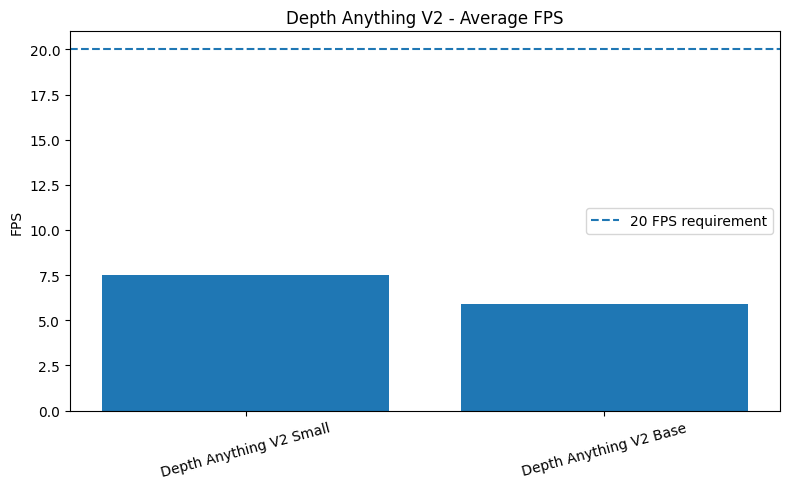

In [ ]:
# 12. Visualize average comparison
plt.figure(figsize=(8, 5))

plt.bar(
    summary_df["Model"],
    summary_df["FPS"]
)

plt.axhline(
    20,
    linestyle="--",
    label="20 FPS requirement"
)

plt.ylabel("FPS")
plt.title("Depth Anything V2 - Average FPS")

plt.legend()
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()